# DS605: Fundamentals of Machine Learning
## Lab Assignment 8: Decision Trees and Support Vector Machines

**Dataset:** UCI Banknote Authentication: 1,372 samples, 4 continuous features extracted from wavelet-transformed images of banknotes, 2 classes.

**Objective.** Implement a Decision Tree and a linear soft-margin SVM from scratch, visualise their decision boundaries, compare them with Scikit-learn, explore non-linear SVM kernels, and compare all models on the full four-feature problem.

**Workflow followed in this notebook**

Banknote Data -> Two-Feature Models + Boundary Plots -> Manual Tree / SVM -> Kernel SVM -> Four-Feature Comparison -> Performance Analysis

**Implementation constraints**
- Both from-scratch algorithms (tree and linear SVM), the train-test split, cross-validation and evaluation metrics are written with NumPy and pandas only.
- Scikit-learn is used only for the reference models it is compared against, for `make_moons` / `make_circles`, and for the kernel SVMs in Parts C and D.
- Two features (variance, skewness) are used for all 2D boundary plots; all four features are used for the final evaluation in Part D.

### Libraries used and why

| Library | Used for | Reason |
|---|---|---|
| NumPy | Tree splitting, impurity, SVM optimisation, metrics, data split | Vectorised array maths; the from-scratch algorithms are built on it |
| pandas | Loading the CSV, summary statistics, result tables | Convenient tabular handling and CSV export |
| Matplotlib | Boundary plots, margin plots, tree diagram, curves | Full control over custom plots (the tree diagram is drawn by hand) |
| time | Training and prediction timing | `perf_counter` is a high-resolution wall clock |
| scikit-learn | `DecisionTreeClassifier`, `SVC`, `make_moons`, `make_circles`, `GridSearchCV` | Reference implementations for comparison and kernel SVMs, as allowed |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

SEED = 42
DATA_PATH = Path("data/data_banknote_authentication.csv")
FIG_DIR, RES_DIR = Path("figures"), Path("results")
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
CMAP_BG = ListedColormap(["#f6c9c4", "#c6dcf2"])     # class 0 / class 1 regions
COLORS = np.array(["#c0392b", "#1f5f9e"])             # class 0 / class 1 points
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.1 | pandas 3.0.5


---
## Data Loading and Exploration

The original UCI file has no header. The four features are statistics of a wavelet-transformed banknote image: **variance**, **skewness**, **curtosis** and **entropy**. The target is the binary `class` (0 or 1); class 1 is treated as the positive class for precision, recall and F1.

In [2]:
FEATURES = ["variance", "skewness", "curtosis", "entropy"]
df = pd.read_csv(DATA_PATH, header=None, names=FEATURES + ["class"])
print("Shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()), "| Exact duplicate rows:", int(df.duplicated().sum()))
display(df.head())
display(df.describe().T)
counts = df["class"].value_counts().sort_index()
pd.DataFrame({"count": counts, "share": counts / len(df)})

Shape: (1372, 5)
Missing values: 0 | Exact duplicate rows: 24


,variance,skewness,curtosis,entropy,class
0,3.6216,8.6661,-2.8073,-0.4470,0
1,4.5459,8.1674,-2.4586,-1.4621,0
2,3.8660,-2.6383,1.9242,0.1065,0
3,3.4566,9.5228,-4.0112,-3.5944,0
4,0.3292,-4.4552,4.5718,-0.9888,0


,count,mean,std,min,25%,50%,75%,max
variance,1372.0,0.4337,2.8428,-7.0421,-1.7730,0.4962,2.8215,6.8248
skewness,1372.0,1.9224,5.8690,-13.7731,-1.7082,2.3197,6.8146,12.9516
curtosis,1372.0,1.3976,4.3100,-5.2861,-1.5750,0.6166,3.1792,17.9274
entropy,1372.0,-1.1917,2.1010,-8.5482,-2.4135,-0.5867,0.3948,2.4495
class,1372.0,0.4446,0.4971,0.0000,0.0000,0.0000,1.0000,1.0000


,count,share
class,,
0,762,0.5554
1,610,0.4446


There are no missing values. The 24 duplicate rows are kept because they are part of the standard benchmark. The classes are moderately balanced (about 56 / 44), so accuracy is meaningful, but precision, recall and F1 are also reported.

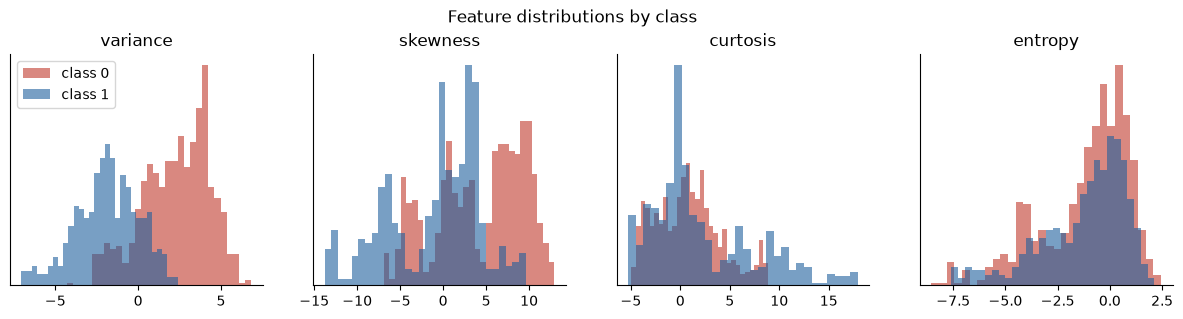

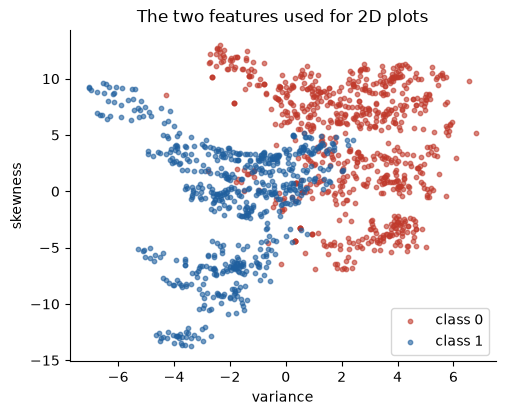

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, f in zip(axes, FEATURES):
    for c in (0, 1):
        ax.hist(df.loc[df["class"] == c, f], bins=30, alpha=0.6, color=COLORS[c], label=f"class {c}")
    ax.set_title(f); ax.set_yticks([])
axes[0].legend()
fig.suptitle("Feature distributions by class", y=1.03)
fig.savefig(FIG_DIR / "data_feature_histograms.png"); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.3))
for c in (0, 1):
    s = df[df["class"] == c]
    ax.scatter(s["variance"], s["skewness"], s=10, alpha=0.6, color=COLORS[c], label=f"class {c}")
ax.set_xlabel("variance"); ax.set_ylabel("skewness"); ax.legend()
ax.set_title("The two features used for 2D plots")
fig.savefig(FIG_DIR / "data_variance_vs_skewness.png"); plt.show()

**Observation.** Variance separates the classes best on its own, skewness adds a second strong direction, and in the variance-skewness plane the classes overlap only in a narrow band. This makes them a good pair for 2D boundary plots, which is also what the assignment specifies.

### Consistent train-test split
A single **stratified 80 / 20 split** with a fixed seed is created once and used in every part, for both the two-feature and the four-feature models, so all results are comparable. Stratification keeps the class ratio identical in both sets. It is implemented in NumPy.

In [4]:
def stratified_split(y, test_size, seed):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        n_test = int(round(test_size * len(idx)))
        test_idx.extend(idx[:n_test]); train_idx.extend(idx[n_test:])
    return np.sort(train_idx), np.sort(test_idx)

X_all = df[FEATURES].to_numpy(dtype=float)
y_all = df["class"].to_numpy(dtype=int)
train_idx, test_idx = stratified_split(y_all, 0.2, SEED)
np.savez(RES_DIR / "split_indices.npz", train_idx=train_idx, test_idx=test_idx)

X_train, X_test = X_all[train_idx], X_all[test_idx]
y_train, y_test = y_all[train_idx], y_all[test_idx]
X2_train, X2_test = X_train[:, :2], X_test[:, :2]          # variance, skewness
print(f"Train: {len(train_idx)}  Test: {len(test_idx)}")
print(f"Class-1 share  train: {y_train.mean():.4f}  test: {y_test.mean():.4f}")

Train: 1098  Test: 274
Class-1 share  train: 0.4444  test: 0.4453


### Shared helpers: metrics and decision-boundary plotting
Metrics are computed from the confusion counts (TP, FP, TN, FN), so they do not depend on Scikit-learn. The boundary helper evaluates a model on a dense grid covering the data and colours each grid point by its predicted class.

In [5]:
def classification_metrics(y_true, y_pred, positive=1):
    tp = np.sum((y_pred == positive) & (y_true == positive))
    fp = np.sum((y_pred == positive) & (y_true != positive))
    fn = np.sum((y_pred != positive) & (y_true == positive))
    tn = np.sum((y_pred != positive) & (y_true != positive))
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y_true), "precision": precision, "recall": recall, "f1": f1,
            "confusion": np.array([[tn, fp], [fn, tp]])}

def make_grid(X, steps=300, pad=0.5):
    x0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, steps)
    x1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, steps)
    g0, g1 = np.meshgrid(x0, x1)
    return g0, g1, np.c_[g0.ravel(), g1.ravel()]

def plot_boundary(ax, predict, X, y, title, xlabel="variance", ylabel="skewness", s=10):
    g0, g1, G = make_grid(X)
    ax.contourf(g0, g1, predict(G).reshape(g0.shape), levels=[-0.5, 0.5, 1.5], cmap=CMAP_BG, alpha=0.8)
    ax.scatter(X[:, 0], X[:, 1], c=COLORS[y], s=s, edgecolor="none", alpha=0.75)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

---
## Part A: Decision Tree from Scratch

### A.1 Impurity measures
For a node with class proportions $p_k$:

$$\text{Gini}(S) = 1 - \sum_k p_k^2, \qquad \text{Entropy}(S) = -\sum_k p_k \log_2 p_k .$$

Both are 0 for a pure node and maximal for an even mix. A split of $S$ into $S_L, S_R$ is scored by the **impurity decrease** (information gain for entropy):

$$\Delta = I(S) - \tfrac{|S_L|}{|S|} I(S_L) - \tfrac{|S_R|}{|S|} I(S_R).$$

The functions accept arrays of class counts so many candidate splits can be scored at once.

Pure node   [10, 0]: gini = 0.0  entropy = -0.0
Even mix    [5, 5] : gini = 0.5  entropy = 1.0


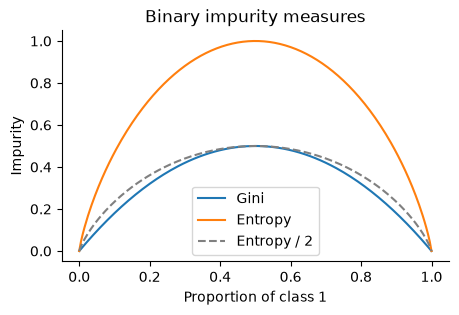

In [6]:
def gini(counts):
    p = counts / counts.sum(axis=-1, keepdims=True)
    return 1.0 - np.sum(p**2, axis=-1)

def entropy(counts):
    p = counts / counts.sum(axis=-1, keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        terms = np.where(p > 0, p * np.log2(p), 0.0)      # 0 log 0 is defined as 0
    return -np.sum(terms, axis=-1)

IMPURITY = {"gini": gini, "entropy": entropy}

print("Pure node   [10, 0]: gini =", gini(np.array([10., 0.])), " entropy =", entropy(np.array([10., 0.])))
print("Even mix    [5, 5] : gini =", gini(np.array([5., 5.])), " entropy =", entropy(np.array([5., 5.])))

p = np.linspace(0, 1, 201); c = np.c_[p, 1 - p]
plt.figure(figsize=(5, 3))
plt.plot(p, gini(c), label="Gini"); plt.plot(p, entropy(c), label="Entropy")
plt.plot(p, entropy(c) / 2, "--", c="0.5", label="Entropy / 2")
plt.xlabel("Proportion of class 1"); plt.ylabel("Impurity"); plt.legend(); plt.title("Binary impurity measures")
plt.savefig(FIG_DIR / "A_impurity_functions.png"); plt.show()

Gini and scaled entropy have almost the same shape, so they usually choose the same splits; entropy penalises mixed nodes slightly more and Gini is cheaper (no logarithm).

### A.2 Choosing the best feature-threshold split
For each feature, the samples are sorted and the **midpoints between consecutive distinct values** are used as candidate thresholds (the same rule Scikit-learn uses). Instead of re-counting classes for every threshold, cumulative class counts give the left and right counts of all candidate splits in one pass, so a feature is scanned in $O(n \log n)$. Splits that would leave fewer than `min_samples_leaf` samples on a side are discarded.

### A.3 Recursive construction, stopping rules and prediction
The tree is grown depth-first. A node becomes a **leaf** when any stopping rule applies:
1. the node is pure,
2. `max_depth` is reached,
3. it has fewer than `min_samples_split` samples,
4. no valid split exists, or the best weighted impurity decrease is below `min_impurity_decrease`.

A leaf predicts the majority class of its training samples, and class probabilities are the leaf's class proportions. Prediction routes whole groups of samples down the tree with boolean masks (instead of looping sample by sample), which keeps grid predictions for boundary plots fast. Feature importances are the total weighted impurity decrease contributed by each feature, normalised to sum to 1 (the same definition as Scikit-learn).

In [7]:
class Node:
    # One tree node. Internal nodes have a feature and threshold; leaves have feature = None.
    def __init__(self, depth, counts, impurity):
        self.depth, self.counts, self.impurity = depth, counts, impurity
        self.n_samples = int(counts.sum())
        self.prediction = int(np.argmax(counts))
        self.feature = self.threshold = self.left = self.right = None
        self.gain = 0.0

    @property
    def is_leaf(self):
        return self.feature is None


class DecisionTreeScratch:
    def __init__(self, criterion="gini", max_depth=None, min_samples_split=2,
                 min_samples_leaf=1, min_impurity_decrease=0.0):
        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.min_impurity_decrease = min_impurity_decrease

    # ---------- training ----------
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        self.n_classes_, self.n_features_ = len(self.classes_), X.shape[1]
        self._impurity = IMPURITY[self.criterion]
        self._n_total = len(y_enc)
        self._importance = np.zeros(self.n_features_)
        self.root_ = self._grow(X, y_enc, depth=0)
        total = self._importance.sum()
        self.feature_importances_ = self._importance / total if total > 0 else self._importance
        return self

    def _best_split(self, X, y, counts):
        n = len(y)
        parent = self._impurity(counts)
        onehot = np.eye(self.n_classes_)[y]
        best_gain, best_feature, best_threshold = 0.0, None, None
        n_left = np.arange(1, n); n_right = n - n_left
        for j in range(X.shape[1]):
            order = np.argsort(X[:, j], kind="mergesort")
            xs = X[order, j]
            left = np.cumsum(onehot[order], axis=0)[:-1]       # class counts left of each cut
            right = counts - left
            valid = (xs[1:] > xs[:-1]) & (n_left >= self.min_samples_leaf) & (n_right >= self.min_samples_leaf)
            if not valid.any():
                continue
            child = (n_left * self._impurity(left) + n_right * self._impurity(right)) / n
            gain = np.where(valid, parent - child, -np.inf)
            i = int(np.argmax(gain))
            if gain[i] > best_gain + 1e-12:
                best_gain, best_feature, best_threshold = gain[i], j, (xs[i] + xs[i + 1]) / 2
        return best_gain, best_feature, best_threshold

    def _grow(self, X, y, depth):
        counts = np.bincount(y, minlength=self.n_classes_).astype(float)
        node = Node(depth, counts, self._impurity(counts))
        if (node.impurity == 0.0 or len(y) < self.min_samples_split
                or (self.max_depth is not None and depth >= self.max_depth)):
            return node
        gain, feature, threshold = self._best_split(X, y, counts)
        weighted_gain = gain * len(y) / self._n_total
        if feature is None or weighted_gain < self.min_impurity_decrease:
            return node
        node.feature, node.threshold, node.gain = feature, threshold, gain
        self._importance[feature] += weighted_gain
        mask = X[:, feature] <= threshold
        node.left = self._grow(X[mask], y[mask], depth + 1)
        node.right = self._grow(X[~mask], y[~mask], depth + 1)
        return node

    # ---------- prediction ----------
    def _route(self, node, X, idx, out):
        if node.is_leaf:
            out[idx] = node.counts / node.n_samples
            return
        mask = X[idx, node.feature] <= node.threshold
        self._route(node.left, X, idx[mask], out)
        self._route(node.right, X, idx[~mask], out)

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        out = np.empty((len(X), self.n_classes_))
        self._route(self.root_, X, np.arange(len(X)), out)
        return out

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]

    # ---------- inspection ----------
    def _nodes(self, node=None):
        node = node or self.root_
        yield node
        if not node.is_leaf:
            yield from self._nodes(node.left); yield from self._nodes(node.right)

    @property
    def n_nodes(self):  return sum(1 for _ in self._nodes())
    @property
    def n_leaves(self): return sum(n.is_leaf for n in self._nodes())
    @property
    def depth(self):    return max(n.depth for n in self._nodes())

    def export_rules(self, feature_names, node=None, indent=""):
        node = node or self.root_
        if node.is_leaf:
            return f"{indent}predict class {self.classes_[node.prediction]}  (samples={node.n_samples}, counts={node.counts.astype(int).tolist()})\n"
        name = feature_names[node.feature]
        return (f"{indent}if {name} <= {node.threshold:.4f}:\n" + self.export_rules(feature_names, node.left, indent + "    ")
                + f"{indent}else:  # {name} > {node.threshold:.4f}\n" + self.export_rules(feature_names, node.right, indent + "    "))

### A.4 Two-feature trees: manual vs Scikit-learn
Both trees are trained on variance and skewness with the same settings (Gini, `max_depth = 3`). Trees do **not** need feature scaling: a split compares one feature with a threshold, so any monotone rescaling moves the threshold but not the partition. Raw feature values are therefore used.

Manual  test accuracy: 0.9380  | nodes = 15, leaves = 8
sklearn test accuracy: 0.9380  | nodes = 15, leaves = 8
Prediction agreement on test set: 1.0000
Root split  manual: variance <= 0.3202 | sklearn: variance <= 0.3202


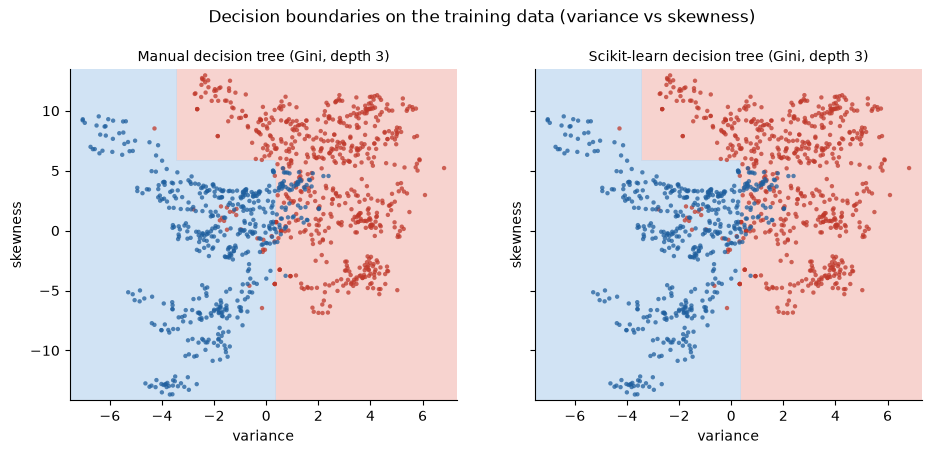

In [8]:
from sklearn.tree import DecisionTreeClassifier

tree_m = DecisionTreeScratch(criterion="gini", max_depth=3).fit(X2_train, y_train)
tree_s = DecisionTreeClassifier(criterion="gini", max_depth=3, random_state=SEED).fit(X2_train, y_train)

pm, ps = tree_m.predict(X2_test), tree_s.predict(X2_test)
print(f"Manual  test accuracy: {np.mean(pm == y_test):.4f}  | nodes = {tree_m.n_nodes}, leaves = {tree_m.n_leaves}")
print(f"sklearn test accuracy: {np.mean(ps == y_test):.4f}  | nodes = {tree_s.tree_.node_count}, leaves = {tree_s.get_n_leaves()}")
print(f"Prediction agreement on test set: {np.mean(pm == ps):.4f}")
print(f"Root split  manual: {FEATURES[tree_m.root_.feature]} <= {tree_m.root_.threshold:.4f} | "
      f"sklearn: {FEATURES[tree_s.tree_.feature[0]]} <= {tree_s.tree_.threshold[0]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
plot_boundary(axes[0], tree_m.predict, X2_train, y_train, "Manual decision tree (Gini, depth 3)")
plot_boundary(axes[1], tree_s.predict, X2_train, y_train, "Scikit-learn decision tree (Gini, depth 3)")
fig.suptitle("Decision boundaries on the training data (variance vs skewness)", y=1.02)
fig.savefig(FIG_DIR / "A_tree_boundaries_manual_vs_sklearn.png"); plt.show()

The boundaries are made of axis-parallel segments because every split tests one feature against a threshold. The two implementations learn the same tree, so the boundaries are identical.

### A.5 Visualising the learned manual tree and its split rules
The diagram is drawn with Matplotlib from the manual tree's own node objects. Leaves are placed left to right in traversal order and each parent is centred above its children; node colour shows the majority class and its strength the purity.

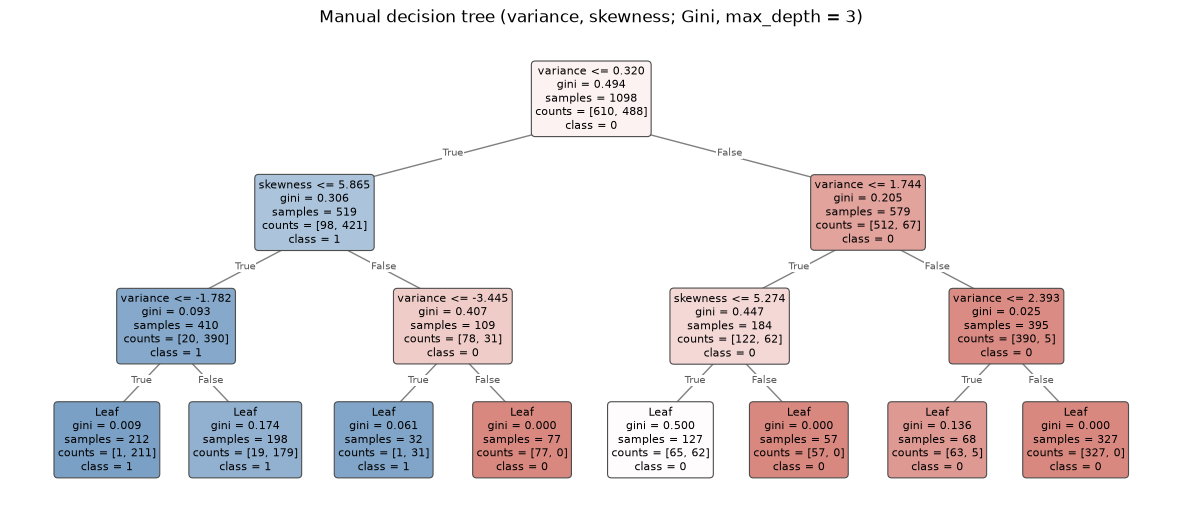

if variance <= 0.3202:
    if skewness <= 5.8654:
        if variance <= -1.7820:
            predict class 1  (samples=212, counts=[1, 211])
        else:  # variance > -1.7820
            predict class 1  (samples=198, counts=[19, 179])
    else:  # skewness > 5.8654
        if variance <= -3.4449:
            predict class 1  (samples=32, counts=[1, 31])
        else:  # variance > -3.4449
            predict class 0  (samples=77, counts=[77, 0])
else:  # variance > 0.3202
    if variance <= 1.7439:
        if skewness <= 5.2736:
            predict class 0  (samples=127, counts=[65, 62])
        else:  # skewness > 5.2736
            predict class 0  (samples=57, counts=[57, 0])
    else:  # variance > 1.7439
        if variance <= 2.3935:
            predict class 0  (samples=68, counts=[63, 5])
        else:  # variance > 2.3935
            predict class 0  (samples=327, counts=[327, 0])



In [9]:
def plot_manual_tree(tree, feature_names, ax, fontsize=8):
    positions, x_counter = {}, [0]
    def place(node):
        if node.is_leaf:
            positions[id(node)] = (x_counter[0], -node.depth); x_counter[0] += 1
        else:
            place(node.left); place(node.right)
            positions[id(node)] = ((positions[id(node.left)][0] + positions[id(node.right)][0]) / 2, -node.depth)
    place(tree.root_)
    crit = tree.criterion
    for node in tree._nodes():
        x, yv = positions[id(node)]
        if not node.is_leaf:
            for child, lab in ((node.left, "True"), (node.right, "False")):
                cx, cy = positions[id(child)]
                ax.plot([x, cx], [yv - 0.18, cy + 0.18], c="0.5", lw=1, zorder=1)
                ax.text((x + cx) / 2, (yv + cy) / 2, lab, fontsize=fontsize - 1, ha="center", color="0.35",
                        bbox=dict(fc="white", ec="none", pad=0.5))
        frac = node.counts / node.n_samples
        cls = node.prediction
        base = np.array([[0.75, 0.22, 0.17], [0.12, 0.37, 0.62]])[cls]
        color = 1 - (1 - base) * (frac[cls] - 0.5) * 2 * 0.6
        head = (f"{feature_names[node.feature]} <= {node.threshold:.3f}\n" if not node.is_leaf else "Leaf\n")
        txt = (f"{head}{crit} = {node.impurity:.3f}\nsamples = {node.n_samples}\n"
               f"counts = {node.counts.astype(int).tolist()}\nclass = {tree.classes_[cls]}")
        ax.text(x, yv, txt, ha="center", va="center", fontsize=fontsize, zorder=2,
                bbox=dict(boxstyle="round,pad=0.35", fc=color, ec="0.3", lw=0.8))
    ax.set_xlim(-0.7, x_counter[0] - 0.3); ax.set_ylim(-tree.depth - 0.6, 0.6); ax.axis("off")

fig, ax = plt.subplots(figsize=(15, 6.2))
plot_manual_tree(tree_m, FEATURES[:2], ax)
ax.set_title("Manual decision tree (variance, skewness; Gini, max_depth = 3)")
fig.savefig(FIG_DIR / "A_manual_tree_diagram.png"); plt.show()

rules = tree_m.export_rules(FEATURES[:2])
(RES_DIR / "A_manual_tree_rules.txt").write_text(rules)
print(rules)

**Reading the tree.** The root split on variance alone already separates most samples; low-variance notes are mostly class 1 and high-variance notes mostly class 0. Deeper splits on skewness and variance refine the overlapping band. Every prediction can be explained as a short chain of if-then rules, which is the main strength of decision trees.

### A.6 Exploring criterion and maximum depth
Both criteria are trained with depths 1 to 12 and unlimited depth, on the two-feature data. For each setting the manual and Scikit-learn trees are compared on test accuracy and on the fraction of test predictions on which they agree.

In [10]:
depths = list(range(1, 13)) + [None]
rows = []
for crit in ("gini", "entropy"):
    for d in depths:
        m = DecisionTreeScratch(criterion=crit, max_depth=d).fit(X2_train, y_train)
        s = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=SEED).fit(X2_train, y_train)
        pm, ps = m.predict(X2_test), s.predict(X2_test)
        rows.append({"criterion": crit, "max_depth": "None" if d is None else d,
                     "manual train acc": np.mean(m.predict(X2_train) == y_train),
                     "manual test acc": np.mean(pm == y_test),
                     "sklearn test acc": np.mean(ps == y_test),
                     "agreement": np.mean(pm == ps),
                     "manual leaves": m.n_leaves, "sklearn leaves": s.get_n_leaves(), "manual depth": m.depth})
explore = pd.DataFrame(rows)
explore.to_csv(RES_DIR / "A_tree_criterion_depth.csv", index=False)
display(explore)
print(f"Mean agreement: {explore['agreement'].mean():.4f} | settings with 100% agreement: "
      f"{(explore['agreement'] == 1).sum()} of {len(explore)}")

,criterion,max_depth,manual train acc,manual test acc,sklearn test acc,agreement,manual leaves,sklearn leaves,manual depth
0,gini,1,0.8497,0.8686,0.8686,1.0000,2,2,1
1,gini,2,0.8925,0.9088,0.9088,1.0000,4,4,2
2,gini,3,0.9199,0.9380,0.9380,1.0000,8,8,3
3,gini,4,0.9426,0.9343,0.9343,1.0000,13,13,4
4,gini,5,0.9463,0.9380,0.9416,0.9964,19,19,5
5,gini,6,0.9590,0.9380,0.9380,1.0000,24,24,6
6,gini,7,0.9699,0.9380,0.9416,0.9964,32,32,7
7,gini,8,0.9763,0.9416,0.9453,0.9964,41,42,8
8,gini,9,0.9863,0.9380,0.9343,0.9891,54,54,9
9,gini,10,0.9973,0.9307,0.9343,0.9964,67,67,10


Mean agreement: 0.9978 | settings with 100% agreement: 12 of 26


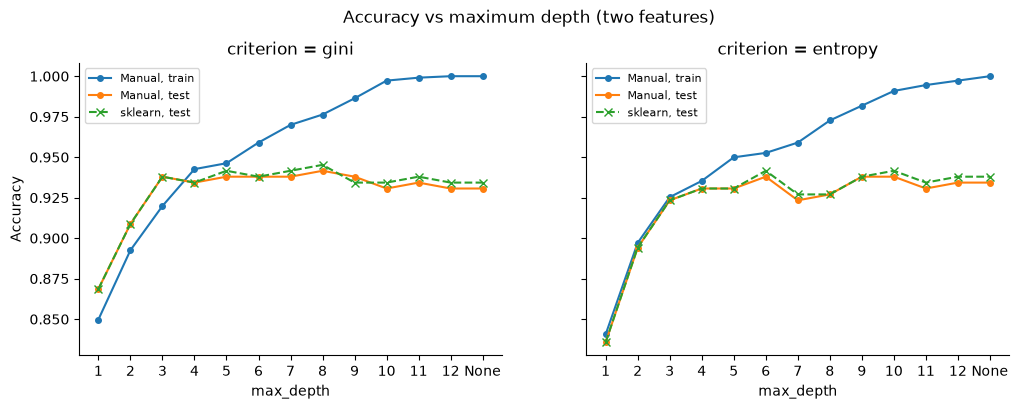

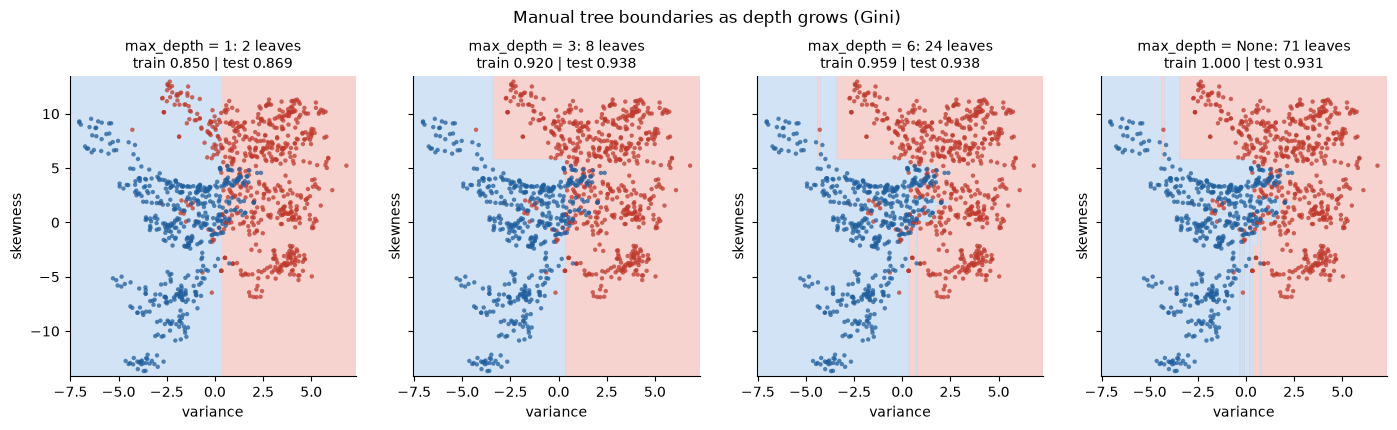

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
xs = [str(d) for d in explore["max_depth"].unique()]
for ax, crit in zip(axes, ("gini", "entropy")):
    e = explore[explore["criterion"] == crit]
    ax.plot(xs, e["manual train acc"], "o-", ms=4, label="Manual, train")
    ax.plot(xs, e["manual test acc"], "o-", ms=4, label="Manual, test")
    ax.plot(xs, e["sklearn test acc"], "x--", ms=6, label="sklearn, test")
    ax.set_title(f"criterion = {crit}"); ax.set_xlabel("max_depth"); ax.legend(fontsize=8)
axes[0].set_ylabel("Accuracy")
fig.suptitle("Accuracy vs maximum depth (two features)", y=1.02)
fig.savefig(FIG_DIR / "A_tree_accuracy_vs_depth.png"); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
for ax, d in zip(axes, (1, 3, 6, None)):
    m = DecisionTreeScratch("gini", max_depth=d).fit(X2_train, y_train)
    plot_boundary(ax, m.predict, X2_train, y_train,
                  f"max_depth = {d}: {m.n_leaves} leaves\ntrain {np.mean(m.predict(X2_train) == y_train):.3f} | "
                  f"test {np.mean(m.predict(X2_test) == y_test):.3f}")
fig.suptitle("Manual tree boundaries as depth grows (Gini)", y=1.05)
fig.savefig(FIG_DIR / "A_tree_boundaries_by_depth.png"); plt.show()

**Observations.**
- The manual tree reproduces Scikit-learn exactly up to depth 4 (identical trees and predictions), and for deeper trees the agreement stays at 98.9% or more (at most 3 of 274 test points differ). The differences come from ties: when two candidate splits have exactly the same impurity decrease, Scikit-learn breaks the tie using a random feature order, while the manual tree takes the first feature found.
- Training accuracy rises to 100% as depth grows, while test accuracy plateaus at about 93-94% from depth 3 onward and is slightly lower for the fully grown tree. The fully grown tree carves small regions around individual points (right-most plot): this is overfitting, which costs little accuracy here only because the two features already overlap in a narrow band.
- Gini and entropy give similar curves; differences at a given depth come from slightly different split choices, not from a systematic advantage.

---
## Part B: Linear SVM from Scratch

### B.1 Feature scaling and label encoding
- **Standardisation** $x' = (x - \mu)/\sigma$ with $\mu, \sigma$ computed on the **training set only** (applying them unchanged to the test set prevents test leakage). SVMs need scaling because the margin is measured with Euclidean distance and the $\lVert w \rVert^2$ penalty treats all weights equally, so a feature with a large range would dominate. Scaling also makes gradient descent better conditioned.
- **Labels** are mapped from {0, 1} to {-1, +1}, which is what the hinge loss $\max(0, 1 - y f(x))$ requires: $y f(x) > 0$ means a correct prediction and $y f(x) \ge 1$ means correct and outside the margin.

In [12]:
class StandardScalerScratch:
    def fit(self, X):
        self.mean_, self.scale_ = X.mean(axis=0), X.std(axis=0)
        return self
    def transform(self, X):
        return (X - self.mean_) / self.scale_

to_pm1 = lambda y: np.where(y == 1, 1.0, -1.0)
to_01 = lambda s: (s > 0).astype(int)

scaler2 = StandardScalerScratch().fit(X2_train)
Z2_train, Z2_test = scaler2.transform(X2_train), scaler2.transform(X2_test)
s_train, s_test = to_pm1(y_train), to_pm1(y_test)
print("Training means after scaling:", Z2_train.mean(0).round(6), "| std:", Z2_train.std(0).round(6))
print("Test means after scaling    :", Z2_test.mean(0).round(4), "(not exactly 0, as expected)")

Training means after scaling: [ 0. -0.] | std: [1. 1.]
Test means after scaling    : [-0.0333 -0.0501] (not exactly 0, as expected)


### B.2 Soft-margin objective and subgradient descent
Scikit-learn's `SVC` minimises the primal soft-margin objective

$$J(w,b) = \tfrac12 \lVert w\rVert^2 + C \sum_{i=1}^{n} \max\big(0,\, 1 - y_i (w^\top x_i + b)\big).$$

Dividing by $nC$ does not change the minimiser and gives an equivalent, better-scaled form that is optimised here:

$$\tilde J(w,b) = \tfrac{\lambda}{2}\lVert w\rVert^2 + \tfrac1n \sum_i \max\big(0,\, 1 - y_i (w^\top x_i + b)\big), \qquad \lambda = \tfrac{1}{nC}.$$

The hinge loss is not differentiable at $y_i f(x_i) = 1$, so a **subgradient** is used. With $V = \{i : y_i f(x_i) < 1\}$ (the margin violators):

$$\partial_w \tilde J = \lambda w - \tfrac1n \sum_{i \in V} y_i x_i, \qquad \partial_b \tilde J = -\tfrac1n \sum_{i \in V} y_i .$$

Design choices:
- **Full-batch** updates: deterministic and fully vectorised; the dataset is small.
- **Bias not regularised**, matching the standard SVM formulation.
- **Learning-rate schedule**: constant by default, or $\eta_t = \eta_0/\sqrt{t+1}$, the classical schedule with convergence guarantees for subgradient methods.
- **Best iterate kept**: subgradient descent does not decrease the objective monotonically, so the parameters with the lowest objective seen are returned.
- The objective is logged in Scikit-learn's $J$ scale so both models can be compared on the same number.

In [13]:
class LinearSVMScratch:
    def __init__(self, C=1.0, lr=0.1, n_iters=2000, schedule="constant"):
        self.C, self.lr, self.n_iters, self.schedule = C, lr, n_iters, schedule

    @staticmethod
    def primal_objective(w, b, X, y, C):
        # Scikit-learn scale: 0.5 ||w||^2 + C * sum of hinge losses
        return 0.5 * w @ w + C * np.maximum(0.0, 1.0 - y * (X @ w + b)).sum()

    def fit(self, X, y):
        n, d = X.shape
        lam = 1.0 / (n * self.C)
        w, b = np.zeros(d), 0.0
        self.objective_history_ = np.empty(self.n_iters)
        self.w_history_, self.b_history_ = np.empty((self.n_iters, d)), np.empty(self.n_iters)
        best_obj = np.inf
        for t in range(self.n_iters):
            margins = y * (X @ w + b)
            viol = margins < 1.0
            grad_w = lam * w - (y[viol, None] * X[viol]).sum(axis=0) / n
            grad_b = -y[viol].sum() / n
            eta = self.lr if self.schedule == "constant" else self.lr / np.sqrt(t + 1)
            w, b = w - eta * grad_w, b - eta * grad_b
            obj = self.primal_objective(w, b, X, y, self.C)
            self.objective_history_[t], self.w_history_[t], self.b_history_[t] = obj, w, b
            if obj < best_obj:
                best_obj, self.coef_, self.intercept_ = obj, w.copy(), b
        self.best_objective_ = best_obj
        return self

    def decision_function(self, X):
        return X @ self.coef_ + self.intercept_

    def predict(self, X):                       # returns -1 / +1
        return np.where(self.decision_function(X) >= 0, 1.0, -1.0)

    def margin_width(self):
        return 2.0 / np.linalg.norm(self.coef_)

### B.3 Two-feature linear SVMs: manual vs Scikit-learn
Both models use $C = 1$ on the standardised variance and skewness features. `SVC(kernel="linear")` is used as the reference because it solves exactly the objective above (LIBSVM, dual formulation). The plots show:
- the separating line $f(x) = 0$ (solid),
- the margins $f(x) = \pm 1$ (dashed),
- **margin violators** of the manual model, i.e. training points with $y_i f(x_i) < 1$ (circled), and misclassified points (marked with a cross),
- the support vectors found by Scikit-learn (circled).

In [14]:
from sklearn.svm import SVC

C0 = 1.0
t0 = time.perf_counter(); svm_m = LinearSVMScratch(C=C0, lr=0.1, n_iters=2000).fit(Z2_train, s_train); t_m = time.perf_counter() - t0
t0 = time.perf_counter(); svm_s = SVC(kernel="linear", C=C0).fit(Z2_train, s_train); t_s = time.perf_counter() - t0
w_s, b_s = svm_s.coef_[0], svm_s.intercept_[0]

margins_m = s_train * svm_m.decision_function(Z2_train)
J = LinearSVMScratch.primal_objective
cosine = svm_m.coef_ @ w_s / (np.linalg.norm(svm_m.coef_) * np.linalg.norm(w_s))
svm_cmp = pd.DataFrame({
    "w_variance": [svm_m.coef_[0], w_s[0]], "w_skewness": [svm_m.coef_[1], w_s[1]], "b": [svm_m.intercept_, b_s],
    "margin width 2/||w||": [svm_m.margin_width(), 2 / np.linalg.norm(w_s)],
    "primal objective J": [J(svm_m.coef_, svm_m.intercept_, Z2_train, s_train, C0), J(w_s, b_s, Z2_train, s_train, C0)],
    "violators / SVs": [int(np.sum(margins_m < 1)), len(svm_s.support_)],
    "train acc": [np.mean(svm_m.predict(Z2_train) == s_train), np.mean(svm_s.predict(Z2_train) == s_train)],
    "test acc": [np.mean(svm_m.predict(Z2_test) == s_test), np.mean(svm_s.predict(Z2_test) == s_test)],
    "fit time (s)": [t_m, t_s]}, index=["Manual (subgradient)", "sklearn SVC linear"])
display(svm_cmp)
print(f"cos(angle between w vectors) = {cosine:.6f}")
print(f"Test prediction agreement     = {np.mean(svm_m.predict(Z2_test) == svm_s.predict(Z2_test)):.4f}")

,w_variance,w_skewness,b,margin width 2/||w||,primal objective J,violators / SVs,train acc,test acc,fit time (s)
Manual (subgradient),-1.9546,-1.1639,-0.2641,0.8792,317.5869,320,0.8734,0.8869,0.1320
sklearn SVC linear,-1.9544,-1.1638,-0.2641,0.8792,317.5870,322,0.8734,0.8869,0.0139


cos(angle between w vectors) = 1.000000
Test prediction agreement     = 1.0000


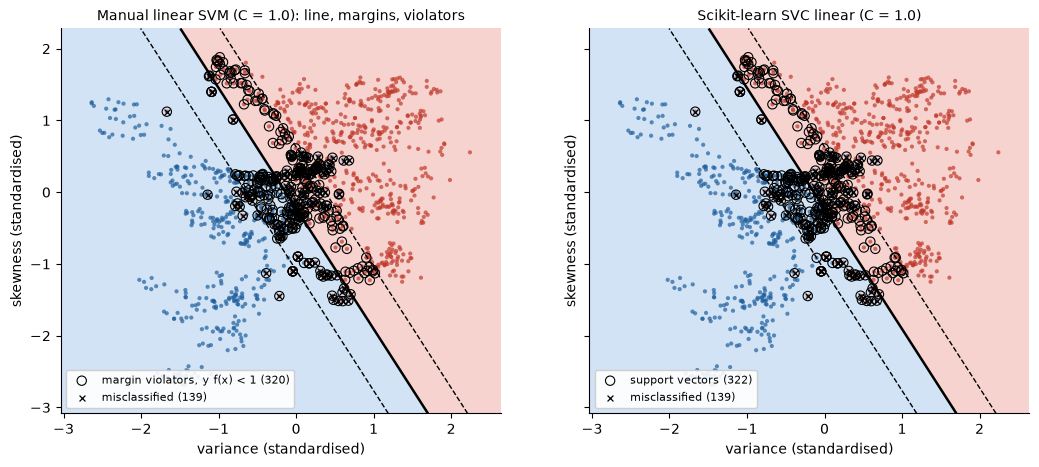

In [15]:
def plot_linear_svm(ax, w, b, X, y, title, highlight=None, highlight_label=""):
    g0, g1, G = make_grid(X, pad=0.4)
    F = (G @ w + b).reshape(g0.shape)
    ax.contourf(g0, g1, (F >= 0).astype(int), levels=[-0.5, 0.5, 1.5], cmap=CMAP_BG, alpha=0.8)
    ax.contour(g0, g1, F, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 1.8, 1])
    ax.scatter(X[:, 0], X[:, 1], c=COLORS[(y > 0).astype(int)], s=9, alpha=0.7, edgecolor="none")
    if highlight is not None:
        ax.scatter(X[highlight, 0], X[highlight, 1], s=45, facecolor="none", edgecolor="k", lw=0.8, label=highlight_label)
    mis = np.sign(X @ w + b) != y
    ax.scatter(X[mis, 0], X[mis, 1], marker="x", c="k", s=18, lw=0.9, label=f"misclassified ({mis.sum()})")
    ax.set_xlabel("variance (standardised)"); ax.set_ylabel("skewness (standardised)")
    ax.set_title(title, fontsize=10); ax.legend(loc="lower left", fontsize=8, framealpha=0.9)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), sharey=True)
plot_linear_svm(axes[0], svm_m.coef_, svm_m.intercept_, Z2_train, s_train,
                f"Manual linear SVM (C = {C0}): line, margins, violators",
                highlight=margins_m < 1, highlight_label=f"margin violators, y f(x) < 1 ({np.sum(margins_m < 1)})")
plot_linear_svm(axes[1], w_s, b_s, Z2_train, s_train, f"Scikit-learn SVC linear (C = {C0})",
                highlight=svm_s.support_, highlight_label=f"support vectors ({len(svm_s.support_)})")
fig.savefig(FIG_DIR / "B_svm_manual_vs_sklearn_margins.png"); plt.show()

**Observation.** The manual model finds essentially the same hyperplane as LIBSVM: the weight vectors point in the same direction (cosine about 1), the objective values agree to several significant figures, and predictions coincide. The margin violators of the manual model correspond to Scikit-learn's support vectors (Scikit-learn also counts points lying exactly on the margin, so its count can be slightly larger). Because the two classes overlap in this 2D view, many points sit inside the margin; these are the only points that influence the solution.

### B.4 Effect of the regularisation parameter C
$C$ trades margin width against training violations. Small $C$ means strong regularisation: a wide margin and many tolerated violations. Large $C$ penalises every violation heavily: a narrower margin that fits the training data more closely. The manual SVM uses more iterations here because large $C$ (small $\lambda$) makes the problem harder for a first-order method.

,C,manual margin,sklearn margin,manual violators,sklearn SVs,manual train acc,manual test acc,sklearn test acc,relative objective gap
0,0.001,3.3878,3.3879,913,914,0.8488,0.8723,0.8723,2.6954e-08
1,0.010,1.6267,1.6266,514,515,0.8743,0.8942,0.8942,2.9029e-09
2,0.100,1.0217,1.0217,358,359,0.8770,0.8905,0.8905,-1.4420e-07
3,1.000,0.8792,0.8792,320,322,0.8734,0.8869,0.8869,-2.7015e-07
4,10.000,0.8526,0.8525,315,317,0.8743,0.8905,0.8905,-4.3242e-07
5,100.000,0.8526,0.8525,315,317,0.8743,0.8905,0.8905,-2.2066e-07


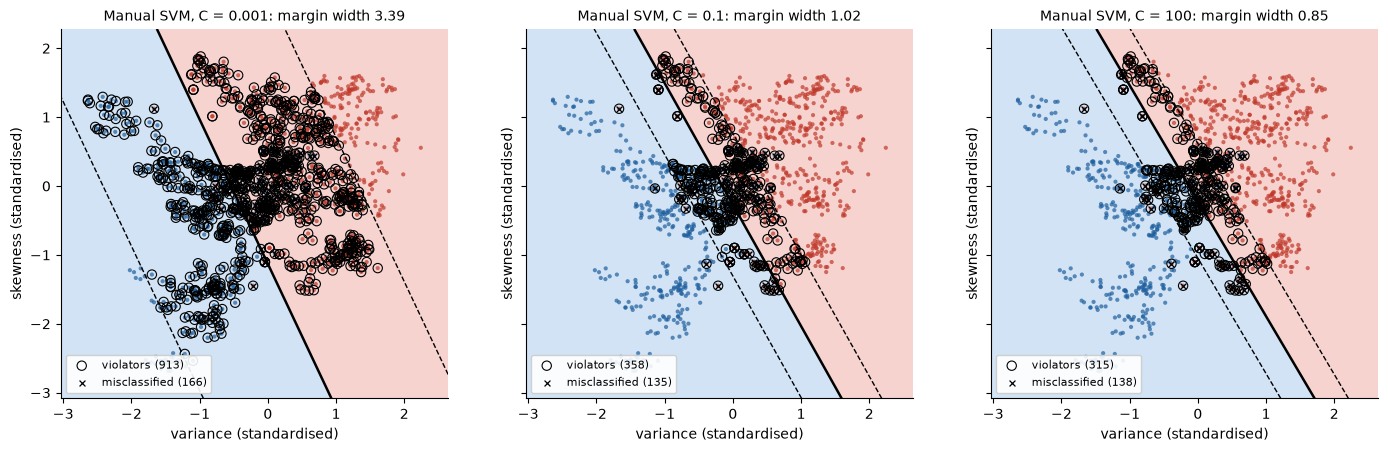

In [16]:
C_values = [0.001, 0.01, 0.1, 1, 10, 100]
rows, fitted = [], {}
for C in C_values:
    m = LinearSVMScratch(C=C, lr=0.1, n_iters=5000).fit(Z2_train, s_train)
    s = SVC(kernel="linear", C=C).fit(Z2_train, s_train)
    ws, bs = s.coef_[0], s.intercept_[0]
    fitted[C] = m
    rows.append({"C": C,
                 "manual margin": m.margin_width(), "sklearn margin": 2 / np.linalg.norm(ws),
                 "manual violators": int(np.sum(s_train * m.decision_function(Z2_train) < 1)),
                 "sklearn SVs": len(s.support_),
                 "manual train acc": np.mean(m.predict(Z2_train) == s_train),
                 "manual test acc": np.mean(m.predict(Z2_test) == s_test),
                 "sklearn test acc": np.mean(s.predict(Z2_test) == s_test),
                 "relative objective gap": (J(m.coef_, m.intercept_, Z2_train, s_train, C) - J(ws, bs, Z2_train, s_train, C))
                                           / J(ws, bs, Z2_train, s_train, C)})
c_df = pd.DataFrame(rows); c_df.to_csv(RES_DIR / "B_svm_effect_of_C.csv", index=False)
display(c_df)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax, C in zip(axes, (0.001, 0.1, 100)):
    m = fitted[C]; mg = s_train * m.decision_function(Z2_train)
    plot_linear_svm(ax, m.coef_, m.intercept_, Z2_train, s_train,
                    f"Manual SVM, C = {C}: margin width {m.margin_width():.2f}",
                    highlight=mg < 1, highlight_label=f"violators ({np.sum(mg < 1)})")
fig.savefig(FIG_DIR / "B_svm_effect_of_C.png"); plt.show()

**Observation.** As $C$ grows the margin shrinks and the number of violators falls, until the solution stabilises (for large $C$ the overlapping points can never be fixed by a linear boundary, so the line barely moves). Test accuracy is slightly lower only for very small $C$, where the regularisation is so strong that the boundary is pulled away from the best position. The objective gap to LIBSVM stays tiny, confirming the optimiser converges for every $C$.

### B.5 Effect of the learning rate and the number of iterations
With $C = 1$ fixed, the manual SVM is trained with several learning rates. The relative objective gap $(J_t - J^*)/J^*$, where $J^*$ is Scikit-learn's objective, is shown on a log scale, together with test accuracy over iterations.

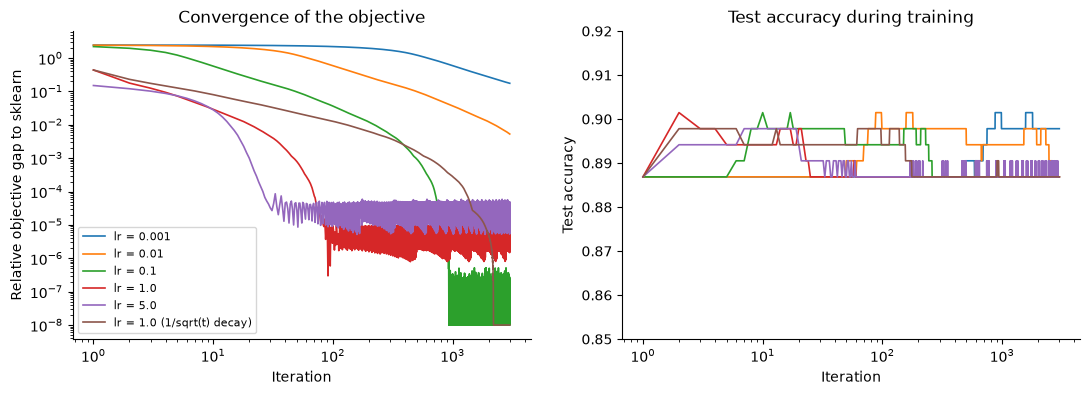

,learning rate,final relative gap (best iterate),test acc
0,0.001,1.7550e-01,0.8978
1,0.01,5.2940e-03,0.8869
2,0.1,-2.7015e-07,0.8869
3,1.0,2.9863e-07,0.8869
4,5.0,5.1954e-06,0.8869
5,1.0 (1/sqrt(t) decay),-3.7113e-07,0.8869


,iterations,relative objective gap,"cos(w, w_sklearn)",test acc
0,10,5.7239e-01,0.9992,0.9015
1,50,9.6838e-02,0.9978,0.8942
2,100,3.6424e-02,0.9991,0.8942
3,500,9.5746e-04,1.0000,0.8869
4,1000,-6.3218e-08,1.0000,0.8869
5,3000,2.6525e-07,1.0000,0.8869


In [17]:
J_star = J(w_s, b_s, Z2_train, s_train, C0)
lrs = [0.001, 0.01, 0.1, 1.0, 5.0]
lr_runs = {lr: LinearSVMScratch(C=C0, lr=lr, n_iters=3000).fit(Z2_train, s_train) for lr in lrs}
lr_runs["1.0 (1/sqrt(t) decay)"] = LinearSVMScratch(C=C0, lr=1.0, n_iters=3000, schedule="invsqrt").fit(Z2_train, s_train)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, m in lr_runs.items():
    gap = np.maximum((m.objective_history_ - J_star) / J_star, 1e-8)
    axes[0].loglog(np.arange(1, m.n_iters + 1), gap, lw=1.2, label=f"lr = {name}")
    test_acc = np.mean(np.sign(Z2_test @ m.w_history_.T + m.b_history_) == s_test[:, None], axis=0)
    axes[1].semilogx(np.arange(1, m.n_iters + 1), test_acc, lw=1.2, label=f"lr = {name}")
axes[0].set_xlabel("Iteration"); axes[0].set_ylabel("Relative objective gap to sklearn")
axes[0].set_title("Convergence of the objective"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("Iteration"); axes[1].set_ylabel("Test accuracy"); axes[1].set_ylim(0.85, 0.92)
axes[1].set_title("Test accuracy during training")
fig.savefig(FIG_DIR / "B_svm_learning_rate_iterations.png"); plt.show()

iters = [10, 50, 100, 500, 1000, 3000]
it_rows = []
for t in iters:
    m = lr_runs[0.1]; w, b = m.w_history_[t - 1], m.b_history_[t - 1]
    it_rows.append({"iterations": t, "relative objective gap": (J(w, b, Z2_train, s_train, C0) - J_star) / J_star,
                    "cos(w, w_sklearn)": w @ w_s / (np.linalg.norm(w) * np.linalg.norm(w_s)),
                    "test acc": np.mean(np.sign(Z2_test @ w + b) == s_test)})
lr_table = pd.DataFrame({"learning rate": list(lr_runs),
                         "final relative gap (best iterate)": [(m.best_objective_ - J_star) / J_star for m in lr_runs.values()],
                         "test acc": [np.mean(m.predict(Z2_test) == s_test) for m in lr_runs.values()]})
display(lr_table)
pd.DataFrame(it_rows)

**Observation.**
- A **too small** learning rate (0.001) is far from the optimum even after thousands of iterations.
- **Moderate rates** (0.1 to 1) converge quickly to within a tiny fraction of the LIBSVM objective.
- A **very large** rate makes the raw objective oscillate around the optimum because each subgradient step overshoots; keeping the best iterate and using a decaying schedule both counter this.
- Test accuracy barely changes after the first few iterations: the direction of $w$ is found almost immediately (cosine with the LIBSVM solution is above 0.99 after 10 iterations), and the remaining iterations mainly adjust the length of $w$, i.e. the margin width and the objective. A few hundred iterations would be enough for prediction purposes.

---
## Part C: Kernel SVM and Non-linear Boundaries

### C.1 Why kernels
A linear SVM can only draw a straight line. A kernel SVM replaces every inner product $x_i^\top x_j$ in the dual problem with a kernel $k(x_i, x_j) = \phi(x_i)^\top \phi(x_j)$, which equals a linear SVM in a transformed feature space $\phi(x)$, without ever computing $\phi$ explicitly (the **kernel trick**). The resulting boundary is linear in $\phi$-space but non-linear in the original space.

| Kernel | $k(x, x')$ | Implicit feature space |
|---|---|---|
| Linear | $x^\top x'$ | the original features |
| Polynomial | $(\gamma\, x^\top x' + r)^d$ | all monomials up to degree $d$ |
| RBF (Gaussian) | $\exp(-\gamma \lVert x - x' \rVert^2)$ | infinite-dimensional; acts as a similarity to each support vector |

### C.2 Non-linear datasets
Two standard 2D datasets are generated with Scikit-learn: interleaving half-moons (`make_moons`) and concentric circles (`make_circles`), both with noise. Each is split 70 / 30 with the same stratified NumPy split and standardised with training statistics.

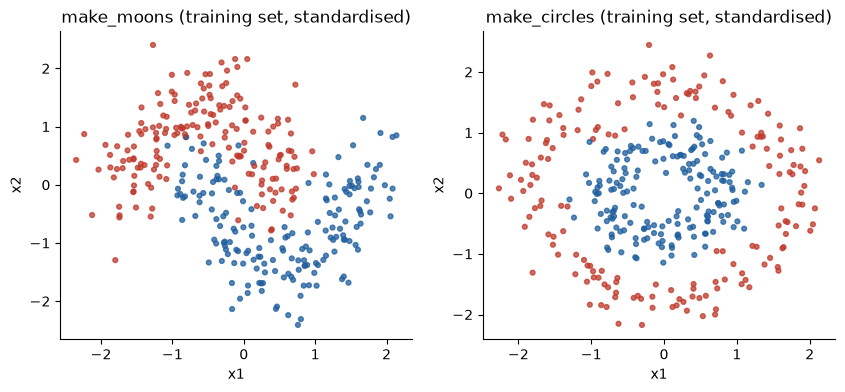

In [18]:
from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import GridSearchCV, StratifiedKFold

def prepare(X, y):
    tr, te = stratified_split(y, 0.3, SEED)
    sc = StandardScalerScratch().fit(X[tr])
    return sc.transform(X[tr]), sc.transform(X[te]), y[tr], y[te]

datasets = {"moons": prepare(*make_moons(n_samples=500, noise=0.25, random_state=SEED)),
            "circles": prepare(*make_circles(n_samples=500, noise=0.12, factor=0.45, random_state=SEED))}

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, (Xtr, Xte, ytr, yte)) in zip(axes, datasets.items()):
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=COLORS[ytr], s=12, alpha=0.75)
    ax.set_title(f"make_{name} (training set, standardised)"); ax.set_xlabel("x1"); ax.set_ylabel("x2")
fig.savefig(FIG_DIR / "C_nonlinear_datasets.png"); plt.show()

### C.3 Training linear, polynomial and RBF SVMs
For a fair comparison every kernel gets its own small hyperparameter search ($C$ for all; degree for polynomial; $\gamma$ for RBF), chosen by 5-fold stratified cross-validation on the training set. The test set is used only for the final scores. The plots show the decision boundary (solid), the $\pm1$ margins (dashed) and the support vectors (circled).

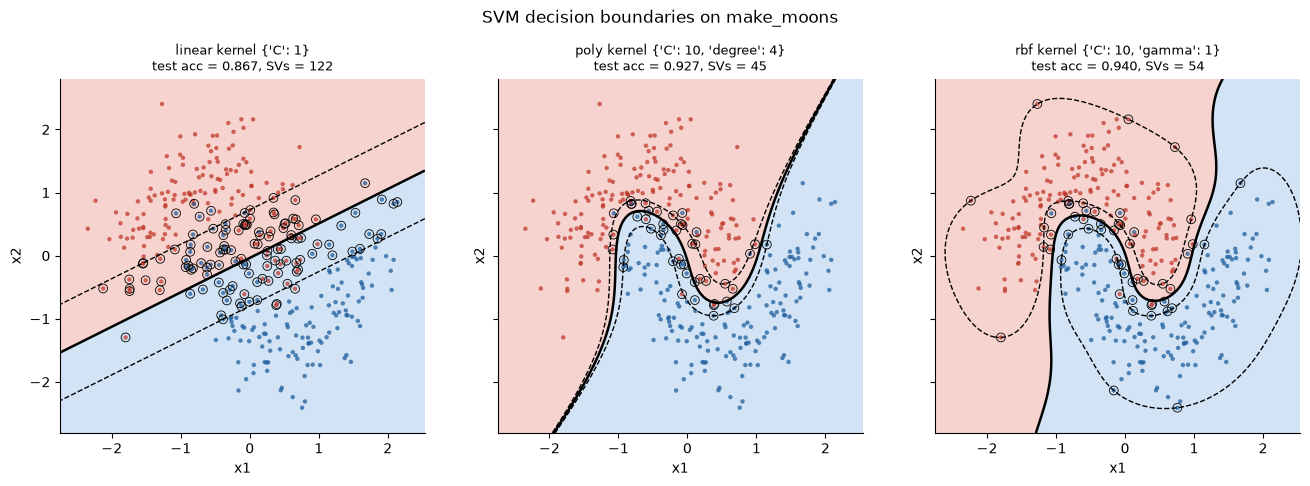

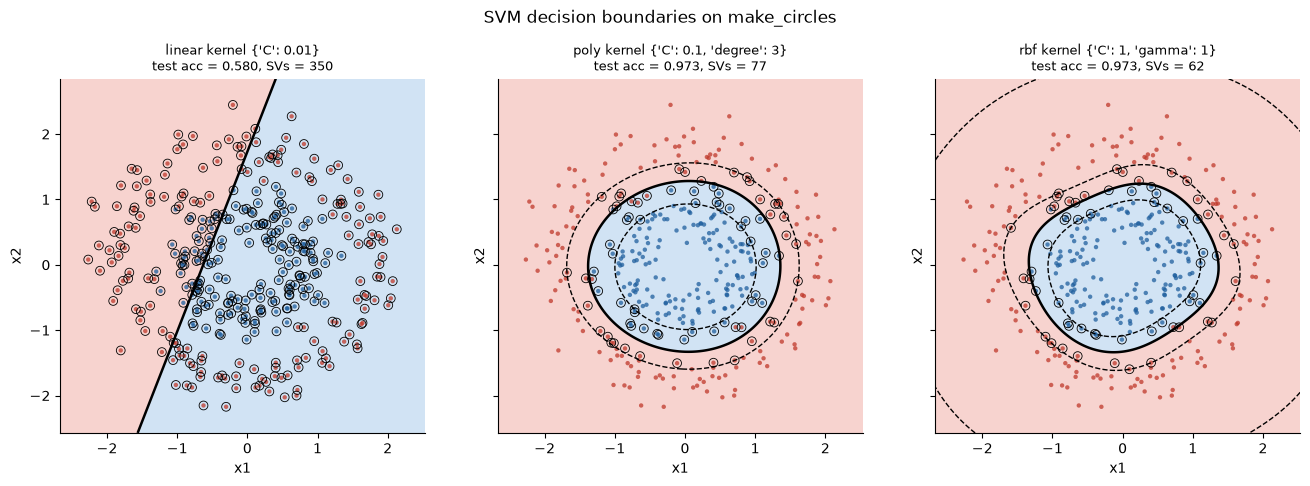

,dataset,kernel,selected params,CV acc,train acc,test acc,support vectors
0,moons,linear,{'C': 1},0.8400,0.8400,0.8667,122
1,moons,poly,"{'C': 10, 'degree': 4}",0.9629,0.9657,0.9267,45
2,moons,rbf,"{'C': 10, 'gamma': 1}",0.9629,0.9686,0.9400,54
3,circles,linear,{'C': 0.01},0.5086,0.5829,0.5800,350
4,circles,poly,"{'C': 0.1, 'degree': 3}",0.9829,0.9800,0.9733,77
5,circles,rbf,"{'C': 1, 'gamma': 1}",0.9829,0.9943,0.9733,62


In [19]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
kernel_grids = {
    "linear": (SVC(kernel="linear"), {"C": [0.01, 0.1, 1, 10, 100]}),
    "poly":   (SVC(kernel="poly", coef0=1, gamma="scale"), {"C": [0.1, 1, 10, 100], "degree": [2, 3, 4, 5]}),
    "rbf":    (SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": [0.1, 0.5, 1, 2, 5]}),
}

def plot_kernel_svm(ax, model, Xtr, ytr, title):
    g0, g1, G = make_grid(Xtr, pad=0.4)
    F = model.decision_function(G).reshape(g0.shape)
    ax.contourf(g0, g1, (F >= 0).astype(int), levels=[-0.5, 0.5, 1.5], cmap=CMAP_BG, alpha=0.8)
    ax.contour(g0, g1, F, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"], linewidths=[1, 1.8, 1])
    ax.scatter(Xtr[:, 0], Xtr[:, 1], c=COLORS[ytr], s=10, alpha=0.75, edgecolor="none")
    sv = model.support_vectors_
    ax.scatter(sv[:, 0], sv[:, 1], s=40, facecolor="none", edgecolor="k", lw=0.6)
    ax.set_title(title, fontsize=9.5); ax.set_xlabel("x1"); ax.set_ylabel("x2")

kernel_rows, kernel_models = [], {}
for dname, (Xtr, Xte, ytr, yte) in datasets.items():
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
    for ax, (kname, (est, grid)) in zip(axes, kernel_grids.items()):
        gs = GridSearchCV(est, grid, cv=cv5).fit(Xtr, ytr)
        m = gs.best_estimator_; kernel_models[(dname, kname)] = m
        te_acc = m.score(Xte, yte)
        kernel_rows.append({"dataset": dname, "kernel": kname, "selected params": gs.best_params_,
                            "CV acc": gs.best_score_, "train acc": m.score(Xtr, ytr), "test acc": te_acc,
                            "support vectors": int(m.n_support_.sum())})
        plot_kernel_svm(ax, m, Xtr, ytr, f"{kname} kernel {gs.best_params_}\n"
                        f"test acc = {te_acc:.3f}, SVs = {m.n_support_.sum()}")
    fig.suptitle(f"SVM decision boundaries on make_{dname}", y=1.03)
    fig.savefig(FIG_DIR / f"C_kernels_{dname}.png"); plt.show()

kernel_df = pd.DataFrame(kernel_rows)
kernel_df.to_csv(RES_DIR / "C_kernel_comparison.csv", index=False)
kernel_df

### C.4 Why a non-linear kernel helps: an explicit feature map
For concentric circles no straight line can separate the classes in $(x_1, x_2)$. Adding a single feature $x_3 = x_1^2 + x_2^2$ (squared distance from the centre) makes them **linearly separable by a plane** in 3D. A degree-2 polynomial kernel contains exactly such quadratic terms, and the RBF kernel goes further. The kernel trick lets the SVM find this plane without constructing the new features.

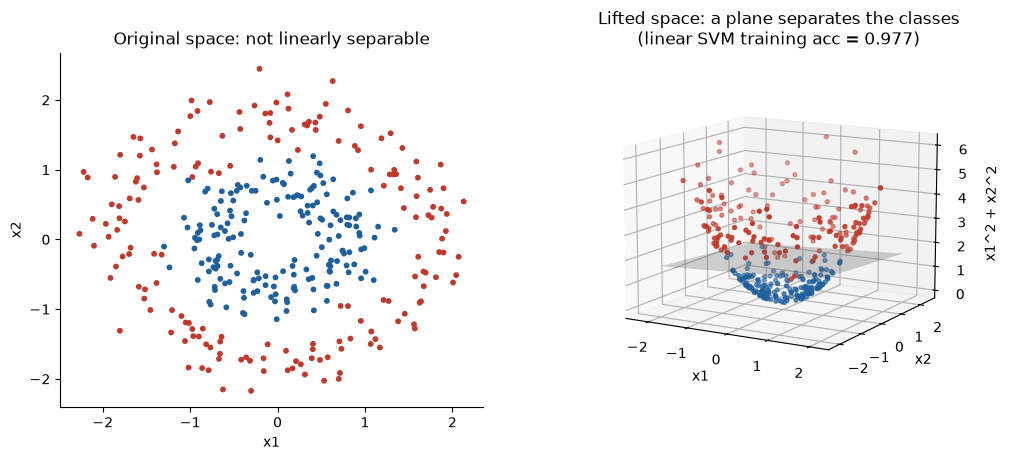

In [20]:
Xtr, _, ytr, _ = datasets["circles"]
x3 = Xtr[:, 0]**2 + Xtr[:, 1]**2
lin3 = SVC(kernel="linear", C=10).fit(np.c_[Xtr, x3], ytr)

fig = plt.figure(figsize=(12, 4.6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.scatter(Xtr[:, 0], Xtr[:, 1], c=COLORS[ytr], s=10)
ax1.set_title("Original space: not linearly separable"); ax1.set_xlabel("x1"); ax1.set_ylabel("x2")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.scatter(Xtr[:, 0], Xtr[:, 1], x3, c=COLORS[ytr], s=8)
w, b = lin3.coef_[0], lin3.intercept_[0]
gx, gy = np.meshgrid(np.linspace(-2, 2, 10), np.linspace(-2, 2, 10))
ax2.plot_surface(gx, gy, -(w[0] * gx + w[1] * gy + b) / w[2], alpha=0.25, color="0.4")
ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_zlabel("x1^2 + x2^2")
ax2.set_title(f"Lifted space: a plane separates the classes\n(linear SVM training acc = {lin3.score(np.c_[Xtr, x3], ytr):.3f})")
ax2.view_init(elev=12, azim=-60)
fig.savefig(FIG_DIR / "C_circles_feature_map_3d.png"); plt.show()

### C.5 RBF width and overfitting
$\gamma$ controls how far the influence of a single support vector reaches. Small $\gamma$ gives a smooth, almost linear boundary (underfitting); very large $\gamma$ gives islands around individual points (overfitting).

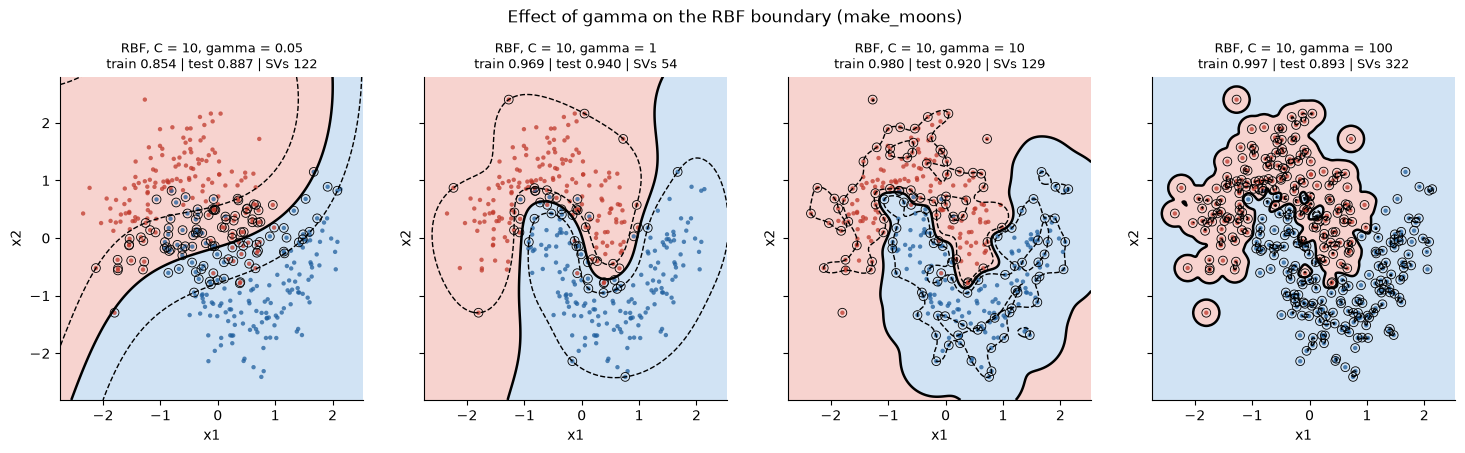

In [21]:
Xtr, Xte, ytr, yte = datasets["moons"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, g in zip(axes, (0.05, 1, 10, 100)):
    m = SVC(kernel="rbf", C=10, gamma=g).fit(Xtr, ytr)
    plot_kernel_svm(ax, m, Xtr, ytr, f"RBF, C = 10, gamma = {g}\ntrain {m.score(Xtr, ytr):.3f} | "
                    f"test {m.score(Xte, yte):.3f} | SVs {m.n_support_.sum()}")
fig.suptitle("Effect of gamma on the RBF boundary (make_moons)", y=1.04)
fig.savefig(FIG_DIR / "C_rbf_gamma_effect.png"); plt.show()

**Observations.**
- The **linear kernel** cannot follow the curved class structure on either dataset; on the circles it is barely better than chance because every straight line cuts both rings.
- The **polynomial kernel** bends the boundary and works well when the needed curvature is of low degree (quadratic for circles), but it can extrapolate wildly far from the data.
- The **RBF kernel** adapts locally and gives the best or joint-best test accuracy on both datasets. Its flexibility must be controlled through $\gamma$ and $C$: as the gamma sweep shows, too large a $\gamma$ memorises the training set (training accuracy near 100%, test accuracy drops, most points become support vectors).
- A non-linear kernel helps whenever the classes are separated by a curved surface; it gives the linear SVM machinery (convex optimisation, margin maximisation) the power of a much richer feature space at low cost.

---
## Part D: Final Comparison on the Full Banknote Dataset (four features)

### D.1 Setup
All models use the four features and the **same train-test split** created at the start.

| Model | Input | Hyperparameters |
|---|---|---|
| Manual decision tree | raw features (scaling not needed) | criterion and max_depth chosen by 5-fold CV (manual CV) |
| Scikit-learn decision tree | raw features | same as the manual tree |
| Manual decision tree, fully grown | raw features | no depth limit; reference for overfitting |
| Manual linear SVM | standardised features | C chosen by 5-fold CV (manual CV) |
| Scikit-learn linear SVM (`SVC`, linear) | standardised features | same C as the manual SVM |
| RBF SVM (`SVC`, rbf) | standardised features | C and gamma chosen by 5-fold CV (`GridSearchCV`) |

The manual SVM uses 3,000 iterations and a learning rate that grows with $C$: $\eta = \max(1, C)$. In the optimised form $\tilde J$ the regularisation strength is $\lambda = 1/(nC)$, so for large $C$ the weight-decay term becomes tiny and a fixed small step needs very many iterations to settle; scaling the step with $C$ compensates. On the four nearly separable features this reaches the LIBSVM objective within about 0.1% for $C \le 10$. For $C = 100$ plain subgradient descent remains slow (a known limitation of first-order methods on weakly regularised problems), so the C grid is limited to $\{0.01, 0.1, 1, 10\}$, the range where the manual optimiser was verified to converge; Part B.4 showed the boundary hardly changes beyond $C = 10$.

Cross-validation for the manual models is implemented in NumPy so that the from-scratch pipeline does not depend on Scikit-learn. All hyperparameters are chosen on the training set only.

Decision tree: best criterion = entropy, max_depth = 6, CV acc = 0.9863
Linear SVM   : best C = 10.0, CV acc = 0.9881
RBF SVM      : best params = {'C': 1, 'gamma': 'scale'}, CV acc = 1.0000


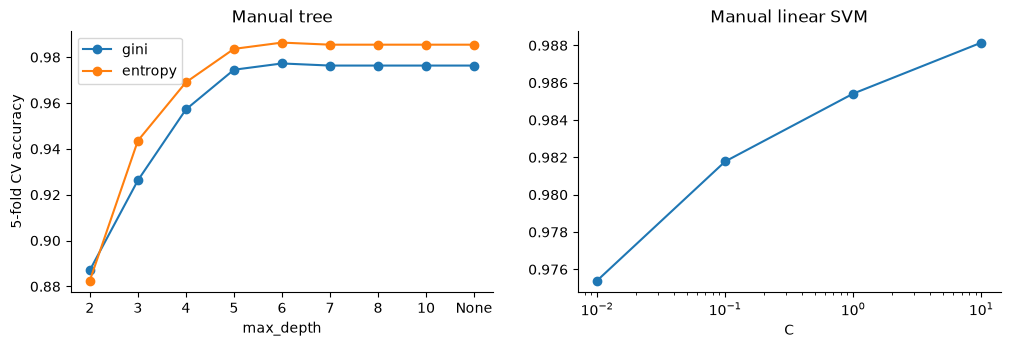

In [22]:
scaler4 = StandardScalerScratch().fit(X_train)
Z4_train, Z4_test = scaler4.transform(X_train), scaler4.transform(X_test)

def stratified_kfold(y, k, seed):
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for c in np.unique(y):
        for i, idx in enumerate(np.array_split(rng.permutation(np.flatnonzero(y == c)), k)):
            folds[i].extend(idx)
    for i in range(k):
        val = np.array(sorted(folds[i])); tr = np.setdiff1d(np.arange(len(y)), val)
        yield tr, val

def cv_accuracy(make_model, X, y, k=5, transform_y=None):
    accs = []
    for tr, val in stratified_kfold(y, k, SEED):
        yt = transform_y(y) if transform_y else y
        m = make_model().fit(X[tr], yt[tr])
        accs.append(np.mean(m.predict(X[val]) == yt[val]))
    return np.mean(accs)

svm_lr = lambda C: max(1.0, C)       # learning-rate rule for the manual SVM in Part D

# Manual decision tree: criterion x max_depth
tree_cv = pd.DataFrame([{"criterion": c, "max_depth": d,
                         "CV acc": cv_accuracy(lambda: DecisionTreeScratch(c, d), X_train, y_train)}
                        for c in ("gini", "entropy") for d in [2, 3, 4, 5, 6, 7, 8, 10, None]])
best_tree = tree_cv.loc[tree_cv["CV acc"].idxmax()]
BEST_CRIT = best_tree["criterion"]
BEST_DEPTH = None if pd.isna(best_tree["max_depth"]) else int(best_tree["max_depth"])
print(f"Decision tree: best criterion = {BEST_CRIT}, max_depth = {BEST_DEPTH}, CV acc = {best_tree['CV acc']:.4f}")

# Manual linear SVM: C
svm_cv = pd.DataFrame([{"C": C, "CV acc": cv_accuracy(lambda: LinearSVMScratch(C=C, lr=svm_lr(C), n_iters=3000),
                                                     Z4_train, y_train, transform_y=to_pm1)}
                       for C in [0.01, 0.1, 1, 10]])
BEST_C = float(svm_cv.loc[svm_cv["CV acc"].idxmax(), "C"])
print(f"Linear SVM   : best C = {BEST_C}, CV acc = {svm_cv['CV acc'].max():.4f}")

# RBF SVM: C x gamma
rbf_gs = GridSearchCV(SVC(kernel="rbf"), {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1, 0.5, 1]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=SEED)).fit(Z4_train, y_train)
print(f"RBF SVM      : best params = {rbf_gs.best_params_}, CV acc = {rbf_gs.best_score_:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for crit in ("gini", "entropy"):
    e = tree_cv[tree_cv["criterion"] == crit]
    axes[0].plot([str(d) for d in e["max_depth"].map(lambda v: "None" if pd.isna(v) else int(v))], e["CV acc"], "o-", label=crit)
axes[0].set_xlabel("max_depth"); axes[0].set_ylabel("5-fold CV accuracy"); axes[0].legend(); axes[0].set_title("Manual tree")
axes[1].semilogx(svm_cv["C"], svm_cv["CV acc"], "o-"); axes[1].set_xlabel("C"); axes[1].set_title("Manual linear SVM")
fig.savefig(FIG_DIR / "D_cross_validation.png"); plt.show()

### D.2 Training, evaluation and timing
Each model is trained on the training set and evaluated on the test set. Training and prediction times are the **median of 5 repetitions** to reduce timing noise. Model complexity is reported as the number of nodes and leaves for trees, and the number of learned parameters or support vectors for SVMs.

In [23]:
def timed(make_model, Xtr, ytr, Xte, repeats=5):
    fit_t, pred_t = [], []
    for _ in range(repeats):
        t0 = time.perf_counter(); m = make_model().fit(Xtr, ytr); fit_t.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); p = m.predict(Xte); pred_t.append(time.perf_counter() - t0)
    return m, p, np.median(fit_t), np.median(pred_t)

specs = {
    "Decision tree (manual)":         (lambda: DecisionTreeScratch(BEST_CRIT, BEST_DEPTH), X_train, X_test, False),
    "Decision tree (sklearn)":        (lambda: DecisionTreeClassifier(criterion=BEST_CRIT, max_depth=BEST_DEPTH, random_state=SEED), X_train, X_test, False),
    "Decision tree (manual, full)":   (lambda: DecisionTreeScratch(BEST_CRIT, None), X_train, X_test, False),
    "Linear SVM (manual)":            (lambda: LinearSVMScratch(C=BEST_C, lr=svm_lr(BEST_C), n_iters=3000), Z4_train, Z4_test, True),
    "Linear SVM (sklearn SVC)":       (lambda: SVC(kernel="linear", C=BEST_C), Z4_train, Z4_test, True),
    "RBF SVM (sklearn SVC)":          (lambda: SVC(kernel="rbf", **rbf_gs.best_params_), Z4_train, Z4_test, False),
}

final_rows, final_models, final_preds = [], {}, {}
for name, (make, Xtr, Xte, pm1) in specs.items():
    ytr = to_pm1(y_train) if pm1 else y_train
    m, p, ft, pt = timed(make, Xtr, ytr, Xte)
    p01 = to_01(p) if pm1 else p
    p_train = to_01(m.predict(Xtr)) if pm1 else m.predict(Xtr)
    met = classification_metrics(y_test, p01)
    if isinstance(m, DecisionTreeScratch):
        complexity = f"{m.n_nodes} nodes, {m.n_leaves} leaves, depth {m.depth}"
    elif isinstance(m, DecisionTreeClassifier):
        complexity = f"{m.tree_.node_count} nodes, {m.get_n_leaves()} leaves, depth {m.get_depth()}"
    elif isinstance(m, LinearSVMScratch):
        complexity = f"5 parameters (w in R^4, b); {int(np.sum(ytr * m.decision_function(Xtr) < 1))} margin violators"
    elif m.kernel == "linear":
        complexity = f"5 parameters (w in R^4, b); {m.n_support_.sum()} support vectors"
    else:
        complexity = f"{m.n_support_.sum()} support vectors"
    final_models[name], final_preds[name] = m, p01
    final_rows.append({"Model": name, "Train acc": np.mean(p_train == y_train), "Test acc": met["accuracy"],
                       "Precision": met["precision"], "Recall": met["recall"], "F1": met["f1"],
                       "Fit time (ms)": ft * 1e3, "Predict time (ms)": pt * 1e3, "Complexity": complexity})

final = pd.DataFrame(final_rows)
final.to_csv(RES_DIR / "D_final_comparison.csv", index=False)
(RES_DIR / "D_final_comparison.md").write_text(final.to_markdown(index=False, floatfmt=".4f"))
final

,Model,Train acc,Test acc,Precision,Recall,F1,Fit time (ms),Predict time (ms),Complexity
0,Decision tree (manual),0.9973,0.9745,0.9675,0.9754,0.9714,11.0872,0.2023,"33 nodes, 17 leaves, depth 6"
1,Decision tree (sklearn),0.9973,0.9745,0.9675,0.9754,0.9714,4.3278,0.1997,"33 nodes, 17 leaves, depth 6"
2,"Decision tree (manual, full)",1.0000,0.9818,0.9835,0.9754,0.9794,9.2844,0.1928,"37 nodes, 19 leaves, depth 7"
3,Linear SVM (manual),0.9918,0.9854,0.9758,0.9918,0.9837,161.3426,0.0276,"5 parameters (w in R^4, b); 34 margin violators"
4,Linear SVM (sklearn SVC),0.9918,0.9854,0.9758,0.9918,0.9837,8.3949,0.5345,"5 parameters (w in R^4, b); 37 support vectors"
5,RBF SVM (sklearn SVC),1.0000,1.0000,1.0000,1.0000,1.0000,6.2229,2.2381,91 support vectors


In [24]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
p = final_preds["RBF SVM (sklearn SVC)"]
print("Check of the NumPy metrics against sklearn.metrics (RBF SVM):")
print("  manual :", {k: round(v, 6) for k, v in classification_metrics(y_test, p).items() if k != "confusion"})
print("  sklearn:", {"accuracy": round(accuracy_score(y_test, p), 6), "precision": round(precision_score(y_test, p), 6),
                     "recall": round(recall_score(y_test, p), 6), "f1": round(f1_score(y_test, p), 6)})
print("\nAgreement manual vs sklearn tree :", np.mean(final_preds["Decision tree (manual)"] == final_preds["Decision tree (sklearn)"]))
print("Agreement manual vs sklearn SVM  :", np.mean(final_preds["Linear SVM (manual)"] == final_preds["Linear SVM (sklearn SVC)"]))
mm, ms_ = final_models["Linear SVM (manual)"], final_models["Linear SVM (sklearn SVC)"]
J_m = J(mm.coef_, mm.intercept_, Z4_train, to_pm1(y_train), BEST_C)
J_s = J(ms_.coef_[0], ms_.intercept_[0], Z4_train, to_pm1(y_train), BEST_C)
cos4 = mm.coef_ @ ms_.coef_[0] / (np.linalg.norm(mm.coef_) * np.linalg.norm(ms_.coef_[0]))
print(f"Linear SVM primal objective  manual: {J_m:.4f} | sklearn: {J_s:.4f} | relative gap: {(J_m - J_s) / J_s:.2e} | cos(w) = {cos4:.6f}")

Check of the NumPy metrics against sklearn.metrics (RBF SVM):
  manual : {'accuracy': np.float64(1.0), 'precision': np.float64(1.0), 'recall': np.float64(1.0), 'f1': np.float64(1.0)}
  sklearn: {'accuracy': 1.0, 'precision': 1.0, 'recall': 1.0, 'f1': 1.0}

Agreement manual vs sklearn tree : 1.0
Agreement manual vs sklearn SVM  : 1.0
Linear SVM primal objective  manual: 285.1960 | sklearn: 285.1432 | relative gap: 1.85e-04 | cos(w) = 0.999990


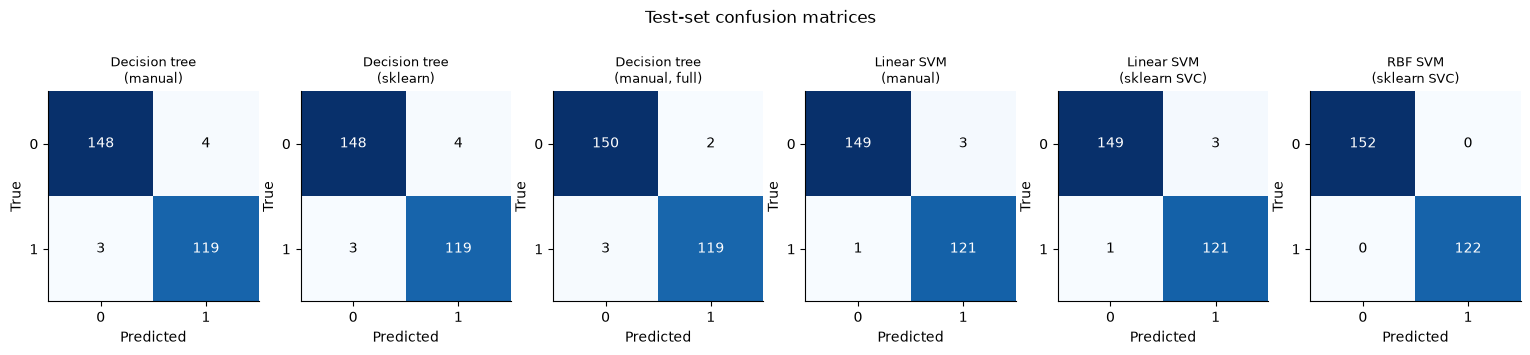

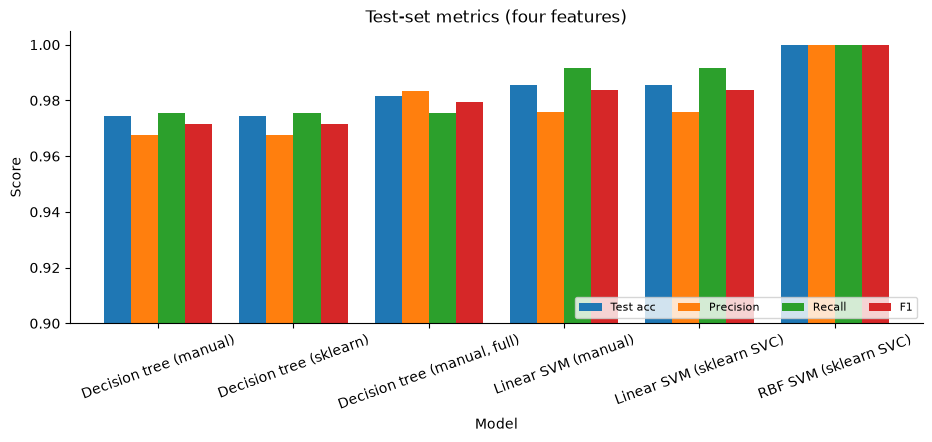

In [25]:
fig, axes = plt.subplots(1, 6, figsize=(19, 3.3))
for ax, (name, p) in zip(axes, final_preds.items()):
    cm = classification_metrics(y_test, p)["confusion"]
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_yticks([0, 1]); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(name.replace(" (", "\n("), fontsize=9)
fig.suptitle("Test-set confusion matrices", y=1.06)
fig.savefig(FIG_DIR / "D_confusion_matrices.png"); plt.show()

ax = final.set_index("Model")[["Test acc", "Precision", "Recall", "F1"]].plot.bar(figsize=(11, 3.8), width=0.8, rot=20)
ax.set_ylim(0.9, 1.005); ax.set_ylabel("Score"); ax.set_title("Test-set metrics (four features)")
ax.legend(loc="lower right", ncol=4, fontsize=8)
plt.savefig(FIG_DIR / "D_metrics_bar.png"); plt.show()

### D.3 Interpretability: rules and feature importance
The depth-limited manual tree can be read as explicit rules, and both trees report how much each feature contributed to impurity reduction. For the linear SVM the standardised weights play a similar role: their sign gives the direction of influence and their magnitude its strength.

In [26]:
mt = final_models["Decision tree (manual)"]
print(mt.export_rules(FEATURES))
(RES_DIR / "D_manual_tree_rules_4features.txt").write_text(mt.export_rules(FEATURES))

importance = pd.DataFrame({
    "Tree importance (manual)": mt.feature_importances_,
    "Tree importance (sklearn)": final_models["Decision tree (sklearn)"].feature_importances_,
    "Linear SVM weight (manual)": final_models["Linear SVM (manual)"].coef_,
    "Linear SVM weight (sklearn)": final_models["Linear SVM (sklearn SVC)"].coef_[0]}, index=FEATURES)
importance

if variance <= 0.7651:
    if skewness <= 5.1608:
        if curtosis <= 0.7473:
            predict class 1  (samples=207, counts=[0, 207])
        else:  # curtosis > 0.7473
            if variance <= -0.1670:
                if skewness <= 0.0072:
                    if variance <= -0.6512:
                        predict class 1  (samples=184, counts=[0, 184])
                    else:  # variance > -0.6512
                        predict class 1  (samples=9, counts=[2, 7])
                else:  # skewness > 0.0072
                    if curtosis <= 4.4621:
                        predict class 1  (samples=14, counts=[0, 14])
                    else:  # curtosis > 4.4621
                        predict class 0  (samples=12, counts=[12, 0])
            else:  # variance > -0.1670
                if entropy <= 0.7646:
                    if curtosis <= 1.1230:
                        predict class 0  (samples=5, counts=[4, 1])
                    else:  # curtosis > 1.1230
        

,Tree importance (manual),Tree importance (sklearn),Linear SVM weight (manual),Linear SVM weight (sklearn)
variance,0.5655,0.5655,-5.5895,-5.6255
skewness,0.2859,0.2859,-6.8590,-6.9656
curtosis,0.1366,0.1366,-5.9886,-6.0481
entropy,0.0120,0.0120,-0.3737,-0.4049


### D.4 Effect of feature scaling
Decision trees should be unaffected by standardisation, while the SVM depends on it. This is checked directly: the manual tree is trained on raw and standardised features, and the manual linear SVM is trained on raw and standardised features with identical optimiser settings.

Tree predictions identical on raw vs standardised data: True


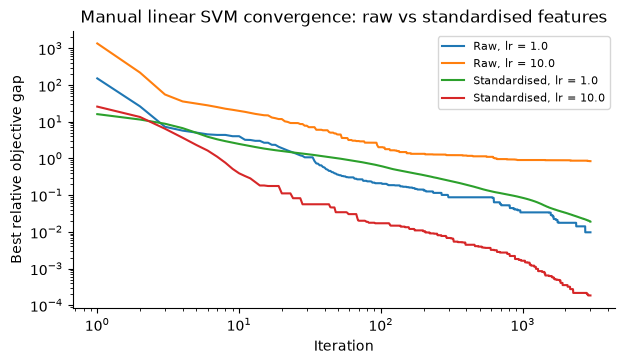

,Input,Feature std range,learning rate,relative objective gap after 3000 its,test acc (manual SVM)
0,Raw,2.11 to 5.83,1.0,0.0097,0.9818
1,Raw,2.11 to 5.83,10.0,0.8447,0.9854
2,Standardised,1.00 to 1.00,1.0,0.0190,0.9891
3,Standardised,1.00 to 1.00,10.0,0.0002,0.9854


In [27]:
t_raw = DecisionTreeScratch(BEST_CRIT, BEST_DEPTH).fit(X_train, y_train)
t_std = DecisionTreeScratch(BEST_CRIT, BEST_DEPTH).fit(Z4_train, y_train)
print("Tree predictions identical on raw vs standardised data:",
      np.array_equal(t_raw.predict(X_test), t_std.predict(Z4_test)))

ytr_pm = to_pm1(y_train)
ref = {"Raw": SVC(kernel="linear", C=BEST_C).fit(X_train, ytr_pm),
       "Standardised": SVC(kernel="linear", C=BEST_C).fit(Z4_train, ytr_pm)}
inputs = {"Raw": (X_train, X_test), "Standardised": (Z4_train, Z4_test)}
rows = []
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, (Xtr_, Xte_) in inputs.items():
    J_ref = J(ref[name].coef_[0], ref[name].intercept_[0], Xtr_, ytr_pm, BEST_C)
    for lr in (1.0, 10.0):
        m = LinearSVMScratch(C=BEST_C, lr=lr, n_iters=3000).fit(Xtr_, ytr_pm)
        gap_curve = (np.minimum.accumulate(m.objective_history_) - J_ref) / J_ref
        ax.loglog(np.arange(1, 3001), np.maximum(gap_curve, 1e-8), label=f"{name}, lr = {lr}")
        rows.append({"Input": name, "Feature std range": f"{Xtr_.std(0).min():.2f} to {Xtr_.std(0).max():.2f}",
                     "learning rate": lr, "relative objective gap after 3000 its": gap_curve[-1],
                     "test acc (manual SVM)": np.mean(m.predict(Xte_) == to_pm1(y_test))})
ax.set_xlabel("Iteration"); ax.set_ylabel("Best relative objective gap"); ax.legend(fontsize=8)
ax.set_title("Manual linear SVM convergence: raw vs standardised features")
fig.savefig(FIG_DIR / "D_scaling_effect_svm.png"); plt.show()
scaling = pd.DataFrame(rows)
scaling

**Observation.** The tree gives identical predictions on raw and standardised data, confirming that trees are scale-invariant. The linear SVM is not: with learning rate 10 the optimiser **diverges on raw features** (objective far from optimal) but converges to within 0.02% on standardised ones. At learning rate 1 the raw run happens to get closer, because larger feature values effectively enlarge each step. In other words, without scaling the right step size depends on the units of the features; standardisation makes the problem well conditioned and the hyperparameters transferable. Scaling also matters for the margin itself, since $\lVert w \rVert^2$ would otherwise penalise features unevenly.

### D.5 Discussion

**Performance.** All models exceed 97% test accuracy, confirming that the four wavelet features make this an easy problem. The RBF SVM is perfect on the test set (and in cross-validation). The linear SVMs come next (98.5%, F1 0.984), followed by the depth-limited trees (97.5%, F1 0.971). The manual and Scikit-learn versions of each algorithm give **identical predictions and metrics**, which validates both from-scratch implementations. With 274 test samples one error is 0.36 percentage points, so the gaps between the top models are a handful of notes.

**Interpretability.** The decision tree is the most interpretable: its 17 leaves are explicit if-then rules that a person can audit, and its feature importances (variance 0.57, skewness 0.29, curtosis 0.14, entropy 0.01) are easy to explain. The linear SVM is also interpretable through its five parameters: on standardised features the weights tell the same story (variance, skewness and curtosis strongly negative, entropy almost zero). The RBF SVM is the least interpretable: its decision depends on kernel similarities to 91 support vectors and has no simple closed-form rule.

**Scaling.** Trees need no scaling. Both SVMs require standardisation, fitted on training data only; for the manual SVM it is also essential for stable gradient descent (D.4).

**Overfitting.** The fully grown tree reaches 100% training accuracy with 19 leaves, several of them covering a single sample, which is classic memorisation; depth limits control this. On this nearly noise-free dataset the full tree happens to score marginally higher on the test set (two notes), and the cross-validated depth of 6 differs from it by only a few nodes, so overfitting is mild here; on the two-feature problem (Part A) it was clearly visible. For SVMs, $C$ and $\gamma$ control overfitting, as shown by the gamma sweep in Part C. The RBF SVM achieves 100% training **and** test accuracy, so its flexibility is not being wasted on noise.

**Model complexity and time.** The linear SVM is the simplest model (5 numbers) and has the fastest prediction, a single dot product per sample. Tree prediction costs at most `depth` comparisons. RBF prediction scales with the number of support vectors, making it the slowest to predict here, though still well under a millisecond for the whole test set. The manual SVM trains slowest (about 100 ms) because it runs 3,000 full-batch iterations in Python, while LIBSVM uses a specialised dual solver in C; the manual tree is within a factor of about 3 of Scikit-learn's Cython implementation.

**Recommendation.** For maximum accuracy the RBF SVM is the best choice. When explanations are required, a depth-limited decision tree or the linear SVM gives almost the same accuracy with a model that can be read directly.

---
## Summary

| Part | Main result |
|---|---|
| A | The from-scratch tree (Gini / entropy, vectorised split search, recursive growth with stopping rules) reproduces Scikit-learn's tree exactly up to depth 4 and agrees on at least 98.9% of test predictions at any depth; depth controls the trade-off between fit and overfitting. |
| B | The subgradient-descent soft-margin SVM reaches the LIBSVM objective within about $10^{-7}$ relative error in 2D. Larger $C$ narrows the margin and reduces violations; learning rates of 0.1 to 1 converge reliably, too small is slow and too large oscillates. |
| C | On moons and circles the linear kernel fails (87% and 58%), while polynomial and RBF kernels reach 93 to 97%; the RBF kernel is the most flexible and needs $\gamma$ and $C$ to be tuned to avoid overfitting. |
| D | On all four features: RBF SVM 100%, linear SVMs 98.5%, depth-6 trees 97.5% test accuracy. Manual and Scikit-learn implementations match on every metric. |